
# Exploratory Data Analysis and Preprocessing of U.S. Oat Prices

## Objective

This notebook examines monthly U.S. oat prices reported by the USDA National Agricultural Statistics Service (NASS).

The analysis focuses on identifying historical trends, seasonal patterns, changes in price variability, and other characteristics relevant to time-series forecasting.

Data cleaning, differencing, smoothing, and transformations will be evaluated to determine which preprocessing steps are appropriate for the dataset.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Display settings
pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (11, 5)


In [2]:

from pathlib import Path
import pandas as pd

# Load the original USDA oat prices dataset
data_path = Path("data") / "USDA_Oats.csv"
df = pd.read_csv(data_path)

# Preview the data
print(f"Dataset shape: {df.shape}")
display(df.head())


Dataset shape: (312, 21)


,Program,Year,Period,Week Ending,Geo Level,State,State ANSI,Ag District,Ag District Code,County,County ANSI,Zip Code,Region,watershed_code,Watershed,Commodity,Data Item,Domain,Domain Category,Value,CV (%)
0,SURVEY,2025,APR,NaN,NATIONAL,US TOTAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,OATS,"OATS - PRICE RECEIVED, MEASURED IN $ / BU",TOTAL,NOT SPECIFIED,3.52,NaN
1,SURVEY,2025,AUG,NaN,NATIONAL,US TOTAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,OATS,"OATS - PRICE RECEIVED, MEASURED IN $ / BU",TOTAL,NOT SPECIFIED,3.27,NaN
2,SURVEY,2025,DEC,NaN,NATIONAL,US TOTAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,OATS,"OATS - PRICE RECEIVED, MEASURED IN $ / BU",TOTAL,NOT SPECIFIED,3.23,NaN
3,SURVEY,2025,FEB,NaN,NATIONAL,US TOTAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,OATS,"OATS - PRICE RECEIVED, MEASURED IN $ / BU",TOTAL,NOT SPECIFIED,3.41,NaN
4,SURVEY,2025,JAN,NaN,NATIONAL,US TOTAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,OATS,"OATS - PRICE RECEIVED, MEASURED IN $ / BU",TOTAL,NOT SPECIFIED,3.47,NaN


In [3]:

# Inspect column names and data types
df.info()

# Check the first and last observations
display(df.head(3))
display(df.tail(3))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Program           312 non-null    object 
 1   Year              312 non-null    int64  
 2   Period            312 non-null    object 
 3   Week Ending       0 non-null      float64
 4   Geo Level         312 non-null    object 
 5   State             312 non-null    object 
 6   State ANSI        0 non-null      float64
 7   Ag District       0 non-null      float64
 8   Ag District Code  0 non-null      float64
 9   County            0 non-null      float64
 10  County ANSI       0 non-null      float64
 11  Zip Code          0 non-null      float64
 12  Region            0 non-null      float64
 13  watershed_code    312 non-null    int64  
 14  Watershed         0 non-null      float64
 15  Commodity         312 non-null    object 
 16  Data Item         312 non-null    object 
 1

,Program,Year,Period,Week Ending,Geo Level,State,State ANSI,Ag District,Ag District Code,County,County ANSI,Zip Code,Region,watershed_code,Watershed,Commodity,Data Item,Domain,Domain Category,Value,CV (%)
0,SURVEY,2025,APR,NaN,NATIONAL,US TOTAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,OATS,"OATS - PRICE RECEIVED, MEASURED IN $ / BU",TOTAL,NOT SPECIFIED,3.52,NaN
1,SURVEY,2025,AUG,NaN,NATIONAL,US TOTAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,OATS,"OATS - PRICE RECEIVED, MEASURED IN $ / BU",TOTAL,NOT SPECIFIED,3.27,NaN
2,SURVEY,2025,DEC,NaN,NATIONAL,US TOTAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,OATS,"OATS - PRICE RECEIVED, MEASURED IN $ / BU",TOTAL,NOT SPECIFIED,3.23,NaN


,Program,Year,Period,Week Ending,Geo Level,State,State ANSI,Ag District,Ag District Code,County,County ANSI,Zip Code,Region,watershed_code,Watershed,Commodity,Data Item,Domain,Domain Category,Value,CV (%)
309,SURVEY,2000,NOV,NaN,NATIONAL,US TOTAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,OATS,"OATS - PRICE RECEIVED, MEASURED IN $ / BU",TOTAL,NOT SPECIFIED,1.22,NaN
310,SURVEY,2000,OCT,NaN,NATIONAL,US TOTAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,OATS,"OATS - PRICE RECEIVED, MEASURED IN $ / BU",TOTAL,NOT SPECIFIED,1.08,NaN
311,SURVEY,2000,SEP,NaN,NATIONAL,US TOTAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,OATS,"OATS - PRICE RECEIVED, MEASURED IN $ / BU",TOTAL,NOT SPECIFIED,0.95,NaN


In [4]:

# Check for missing values and duplicates
print("Missing values:")
display(df.isna().sum())

print("Duplicate rows:", df.duplicated().sum())

# Summary statistics
display(df.describe(include="all"))


Missing values:


Program               0
Year                  0
Period                0
Week Ending         312
Geo Level             0
State                 0
State ANSI          312
Ag District         312
Ag District Code    312
County              312
County ANSI         312
Zip Code            312
Region              312
watershed_code        0
Watershed           312
Commodity             0
Data Item             0
Domain                0
Domain Category       0
Value                 0
CV (%)              312
dtype: int64

Duplicate rows: 0


,Program,Year,Period,Week Ending,Geo Level,State,State ANSI,Ag District,Ag District Code,County,County ANSI,Zip Code,Region,watershed_code,Watershed,Commodity,Data Item,Domain,Domain Category,Value,CV (%)
count,312,312.000000,312,0.0,312,312,0.0,0.0,0.0,0.0,0.0,0.0,0.0,312.0,0.0,312,312,312,312,312.000000,0.0
unique,1,NaN,12,NaN,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,1,1,NaN,NaN
top,SURVEY,NaN,APR,NaN,NATIONAL,US TOTAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,OATS,"OATS - PRICE RECEIVED, MEASURED IN $ / BU",TOTAL,NOT SPECIFIED,NaN,NaN
freq,312,NaN,26,NaN,312,312,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,312,312,312,312,NaN,NaN
mean,NaN,2012.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,2.776474,NaN
std,NaN,7.512048,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,1.046597,NaN
min,NaN,2000.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.930000,NaN
25%,NaN,2006.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,1.950000,NaN
50%,NaN,2012.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,2.700000,NaN
75%,NaN,2019.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,3.475000,NaN



## 2. Data Cleaning and Preparation

The original USDA NASS dataset contains 21 columns, including geographic and administrative information that is not needed for this analysis.

The data will be reduced to the year, month, and price variables. Dates will be converted to a monthly time index, and observations will be sorted chronologically. The resulting series will be checked for duplicate dates and missing months before further analysis.


In [5]:

# Keep relevant columns
oats = df[["Year", "Period", "Value"]].copy()

# Convert year and month to dates
oats["Date"] = pd.to_datetime(
    oats["Year"].astype(str) + "-" + oats["Period"],
    format="%Y-%b"
)

# Rename and organize columns
oats = oats.rename(columns={"Value": "Price"})
oats["Price"] = pd.to_numeric(oats["Price"], errors="coerce")

# Sort chronologically and set monthly index
oats = oats.set_index("Date")[["Price"]].sort_index()
oats = oats.asfreq("MS")

display(oats.head())
display(oats.tail())


,Price
Date,
2000-01-01,1.20
2000-02-01,1.27
2000-03-01,1.28
2000-04-01,1.35
2000-05-01,1.31


,Price
Date,
2025-08-01,3.27
2025-09-01,3.12
2025-10-01,3.11
2025-11-01,3.06
2025-12-01,3.23


In [6]:

print("Start:", oats.index.min())
print("End:", oats.index.max())
print("Observations:", len(oats))
print("Missing prices:", oats["Price"].isna().sum())
print("Duplicate dates:", oats.index.duplicated().sum())
print("Frequency:", oats.index.freqstr)


Start: 2000-01-01 00:00:00
End: 2025-12-01 00:00:00
Observations: 312
Missing prices: 0
Duplicate dates: 0
Frequency: MS



## 3. Exploratory Data Analysis

This section examines the distribution and historical behavior of monthly U.S. oat prices. Descriptive statistics and visualizations are used to identify trends, unusual observations, and potential changes in price variability.


In [7]:

# Summary statistics for monthly oat prices
display(oats["Price"].describe())

# Additional distribution statistics
print("Skewness:", round(oats["Price"].skew(), 3))
print("Kurtosis:", round(oats["Price"].kurtosis(), 3))


count    312.000000
mean       2.776474
std        1.046597
min        0.930000
25%        1.950000
50%        2.700000
75%        3.475000
max        6.610000
Name: Price, dtype: float64

Skewness: 0.706
Kurtosis: 0.807


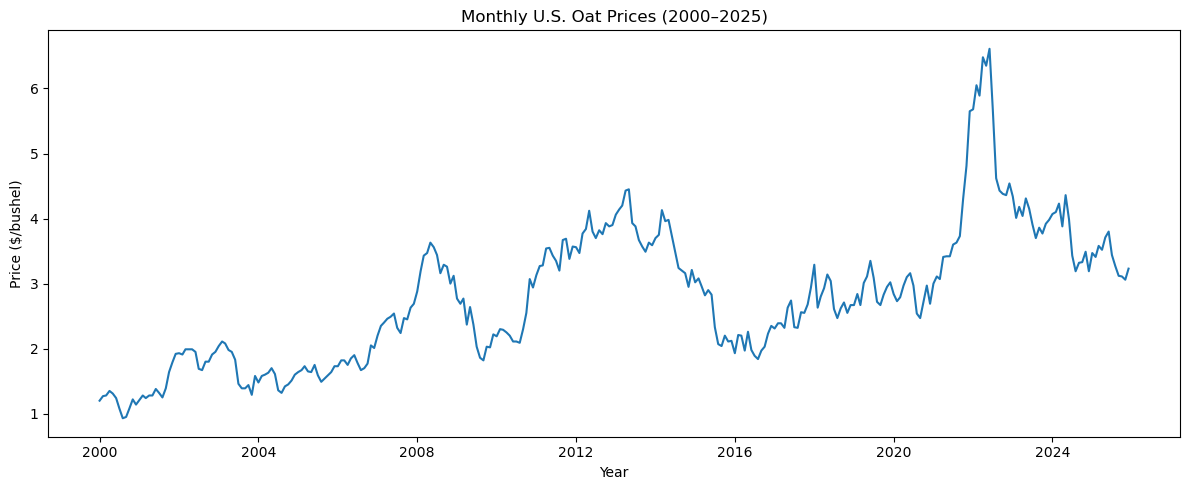

In [8]:

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(oats.index, oats["Price"], linewidth=1.5)

ax.set(
    title="Monthly U.S. Oat Prices (2000–2025)",
    xlabel="Year",
    ylabel="Price ($/bushel)"
)

plt.tight_layout()
plt.show()


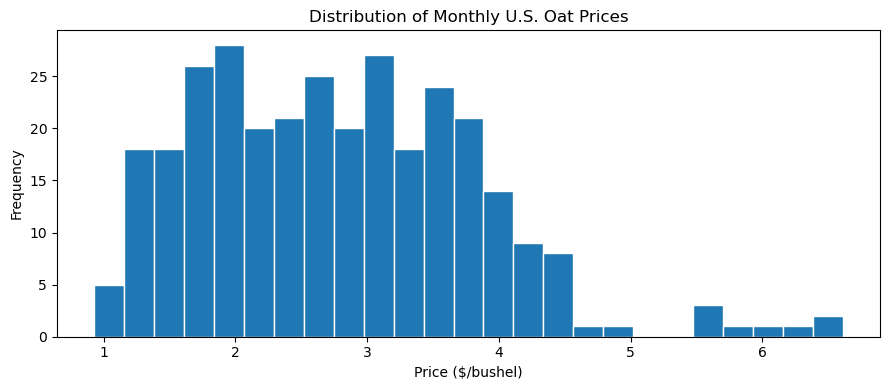

In [9]:

fig, ax = plt.subplots(figsize=(9, 4))

ax.hist(oats["Price"], bins=25, edgecolor="white")

ax.set(
    title="Distribution of Monthly U.S. Oat Prices",
    xlabel="Price ($/bushel)",
    ylabel="Frequency"
)

plt.tight_layout()
plt.show()



### Initial Findings

Monthly U.S. oat prices averaged approximately 2.78 USD per bushel between 2000 and 2025, ranging from 0.93 to 6.61 USD. The distribution is moderately right-skewed (0.706), indicating that higher prices extend further into the upper tail. The relatively large standard deviation also suggests considerable variation in prices over the study period.

These findings support further investigation of historical price trends, seasonality, and changes in variability before selecting preprocessing methods.


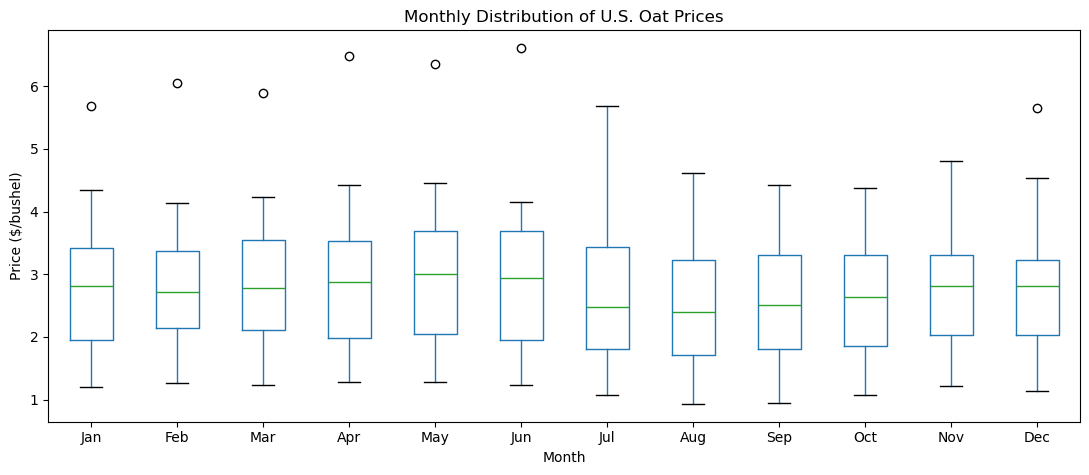

In [11]:

# Compare oat prices by calendar month
monthly = oats.copy()
monthly["Month"] = monthly.index.month

fig, ax = plt.subplots(figsize=(11, 5))

monthly.boxplot(
    column="Price",
    by="Month",
    ax=ax,
    grid=False
)

ax.set(
    title="Monthly Distribution of U.S. Oat Prices",
    xlabel="Month",
    ylabel="Price ($/bushel)"
)

ax.set_xticklabels(
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.suptitle("")
plt.tight_layout()
plt.show()



### Monthly Price Distribution

Monthly oat prices show some differences throughout the year, suggesting potential seasonality. Median prices are generally higher during the first half of the year, peaking around May, and lower during the summer months, particularly August.

However, the distributions overlap considerably, indicating that seasonal differences may be relatively small compared with overall price fluctuations. Further analysis is needed to determine whether these patterns are consistent across years.


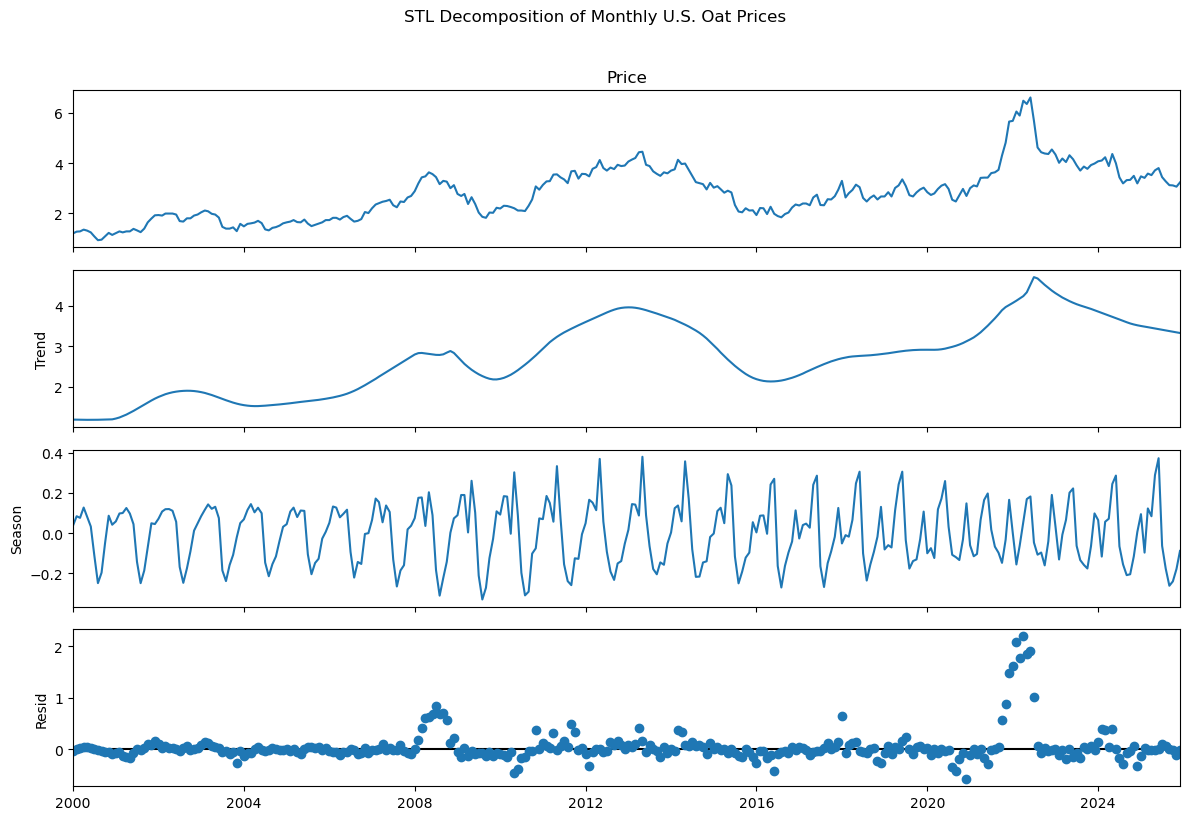

In [12]:

# STL decomposition with annual seasonality
stl = STL(oats["Price"], period=12, robust=True).fit()

# Plot decomposition
fig = stl.plot()
fig.set_size_inches(12, 8)
fig.suptitle("STL Decomposition of Monthly U.S. Oat Prices",
             y=1.02)

plt.tight_layout()
plt.show()



### STL Decomposition Findings

The STL decomposition shows that monthly U.S. oat prices contain both long-term trends and recurring seasonal fluctuations. The trend component captures several periods of rising and falling prices, including a substantial increase around 2022.

The seasonal component suggests an annual pattern, although its strength and consistency vary over time. The remainder also contains unusually large deviations, particularly around 2021 to 2022, indicating that some price movements are not fully explained by the trend and seasonal components.

Overall, the results suggest that trend and seasonality should both be considered when developing forecasting models.


In [15]:

# Seasonal strength from STL decomposition
seasonal_strength = max(
    0,
    1 - np.var(stl.resid) /
        np.var(stl.seasonal + stl.resid)
)

print(f"Seasonal strength: {seasonal_strength:.3f}")


Seasonal strength: 0.167



### Seasonal Strength

The STL decomposition produced a seasonal strength of 0.167, indicating relatively weak seasonality in monthly U.S. oat prices. Although the seasonal component shows recurring annual fluctuations, these patterns explain relatively little of the variation remaining after accounting for the trend.

This suggests that nonseasonal price movements may have a greater influence on the series. However, seasonal forecasting methods may still be worth evaluating to determine whether they improve predictive accuracy.



## 4. Autocorrelation and Stationarity

Autocorrelation measures the relationship between observations at different time lags. The ACF and PACF plots will be used to investigate persistence, potential seasonality, and whether the oat price series may require differencing.

Because the data is monthly, particular attention will be given to lags 12, 24, and 36, which correspond to annual intervals.


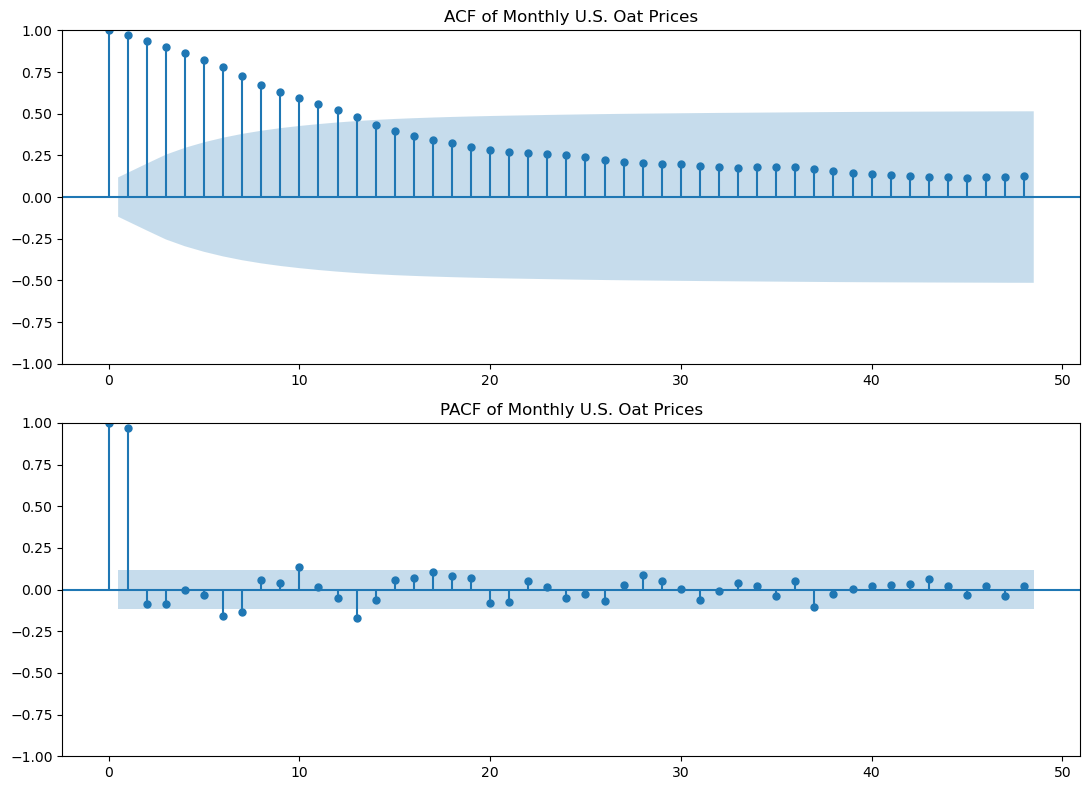

In [16]:

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Use training data for preprocessing diagnostics
train = oats.loc[:"2022-12-01", "Price"]

fig, axes = plt.subplots(2, 1, figsize=(11, 8))

plot_acf(train, lags=48, ax=axes[0])
axes[0].set_title("ACF of Monthly U.S. Oat Prices")

plot_pacf(train, lags=48, method="ywm", ax=axes[1])
axes[1].set_title("PACF of Monthly U.S. Oat Prices")

plt.tight_layout()
plt.show()



### Autocorrelation Findings

The ACF shows strong positive autocorrelation that decreases gradually across many lags, suggesting that the original oat price series may be nonstationary. The PACF has a prominent spike at lag 1, indicating a strong relationship between consecutive monthly prices.

Neither plot shows a particularly clear annual seasonal pattern at lags 12, 24, or 36. Combined with the relatively low seasonal strength of 0.167, this suggests that seasonality may be less influential than longer-term price movements.

These findings support further stationarity testing to determine whether differencing is necessary.


In [17]:

from statsmodels.tsa.stattools import adfuller, kpss

# Augmented Dickey-Fuller test
adf_result = adfuller(train, autolag="AIC")

# KPSS test
kpss_result = kpss(train, regression="c", nlags="auto")

print("ADF Test")
print(f"Statistic: {adf_result[0]:.3f}")
print(f"p-value: {adf_result[1]:.4f}")

print("\nKPSS Test")
print(f"Statistic: {kpss_result[0]:.3f}")
print(f"p-value: {kpss_result[1]:.4f}")


ADF Test
Statistic: -1.697
p-value: 0.4325

KPSS Test
Statistic: 1.335
p-value: 0.0100


C:\Users\marin\AppData\Local\Temp\ipykernel_31588\3542931088.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(train, regression="c", nlags="auto")



### Stationarity Test Results

The ADF test produced a p-value of 0.4325, providing insufficient evidence to reject the presence of a unit root. The KPSS test returned a p-value below 0.01, indicating that the series is not stationary around a constant mean.

These findings are consistent with the slowly declining ACF and suggest that differencing may be necessary to stabilize the mean before forecasting.



## 5. Differencing

The stationarity tests suggest that the original oat price series is nonstationary. First differencing will be applied to examine whether month-to-month price changes exhibit more stable statistical properties.


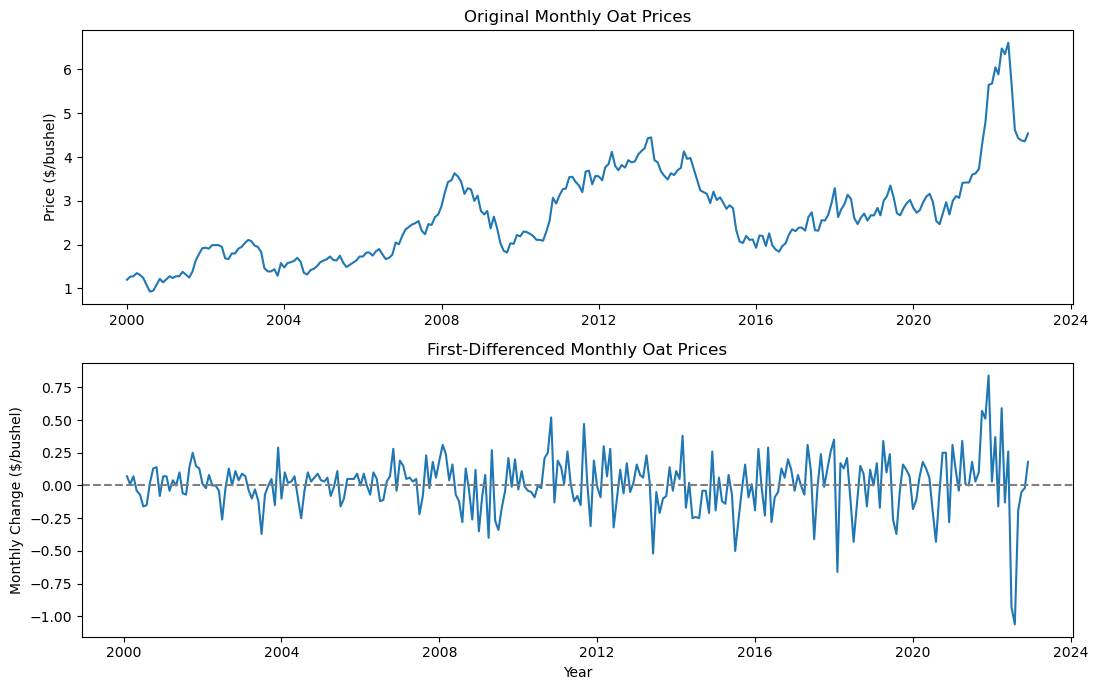

In [18]:

# Calculate first differences using training data
train_diff = train.diff().dropna()

fig, axes = plt.subplots(2, 1, figsize=(11, 7))

axes[0].plot(train)
axes[0].set(
    title="Original Monthly Oat Prices",
    ylabel="Price ($/bushel)"
)

axes[1].plot(train_diff)
axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set(
    title="First-Differenced Monthly Oat Prices",
    xlabel="Year",
    ylabel="Monthly Change ($/bushel)"
)

plt.tight_layout()
plt.show()


In [19]:

# Stationarity tests after first differencing
adf_diff = adfuller(train_diff, autolag="AIC")
kpss_diff = kpss(train_diff, regression="c", nlags="auto")

print("First-Differenced Series")

print(f"ADF p-value: {adf_diff[1]:.4f}")
print(f"KPSS p-value: {kpss_diff[1]:.4f}")


First-Differenced Series
ADF p-value: 0.0000
KPSS p-value: 0.1000


C:\Users\marin\AppData\Local\Temp\ipykernel_31588\3988710236.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_diff = kpss(train_diff, regression="c", nlags="auto")



### First-Differencing Results

First differencing substantially improved the stationarity of the oat price series. The ADF test produced a p-value below 0.0001, while the KPSS test produced a p-value above 0.10. Both results support stationarity after differencing.

These findings suggest that one order of nonseasonal differencing is sufficient to stabilize the mean of the series. Additional differencing does not appear necessary at this stage.


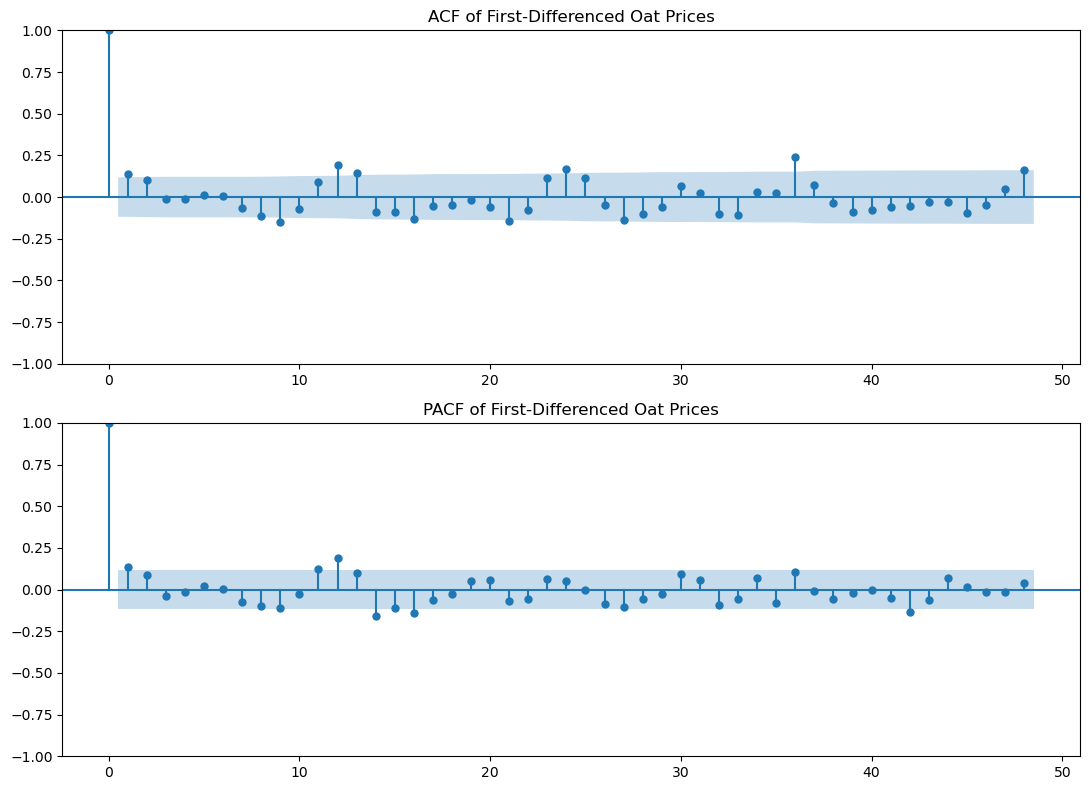

In [21]:

fig, axes = plt.subplots(2, 1, figsize=(11, 8))

plot_acf(train_diff, lags=48, ax=axes[0])
axes[0].set_title("ACF of First-Differenced Oat Prices")

plot_pacf(train_diff, lags=48, method="ywm", ax=axes[1])
axes[1].set_title("PACF of First-Differenced Oat Prices")

plt.tight_layout()
plt.show()



### Autocorrelation After Differencing

After first differencing, the ACF no longer shows the slow decline observed in the original series, indicating that much of the persistence has been removed. Most autocorrelations are relatively small, although some positive correlations remain around seasonal lags 12, 24, and 36.

The PACF also shows relatively small correlations, with a few noticeable spikes around annual seasonal lags. Combined with the ADF and KPSS results, these findings suggest that first differencing is sufficient to address nonstationarity, although some seasonal structure may remain.



## 6. Smoothing

A 12-month moving average will be used to smooth short-term fluctuations and examine the underlying movement in oat prices.

Because the data is monthly, a 12-month window represents one year of observations. The smoothed series will be compared with the original prices to determine whether it provides a clearer view of longer-term trends.


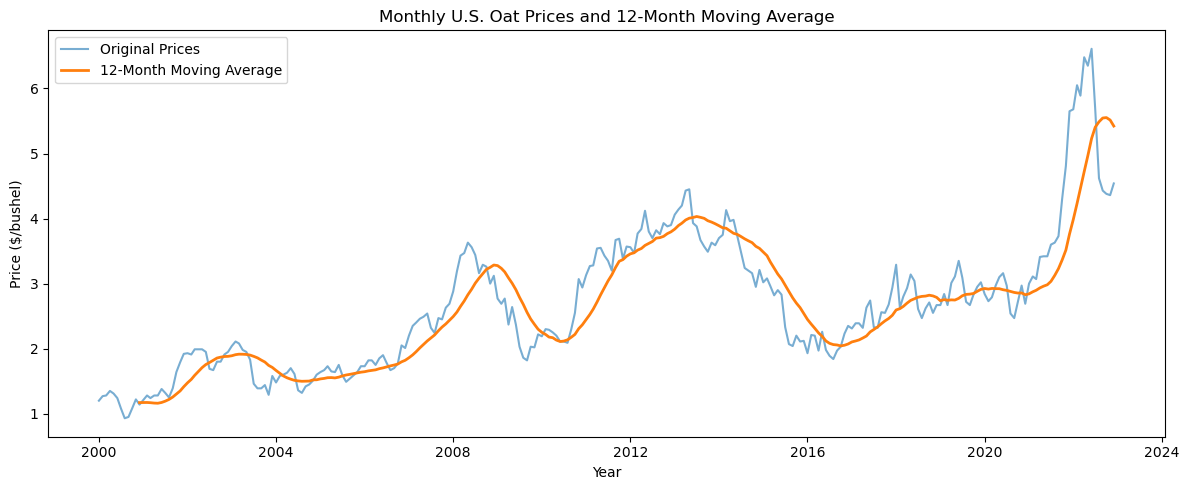

In [23]:

# Calculate a trailing 12-month moving average
train_ma12 = train.rolling(window=12).mean()

# Compare original and smoothed prices
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    train.index, train,
    label="Original Prices",
    alpha=0.6
)

ax.plot(
    train_ma12.index, train_ma12,
    label="12-Month Moving Average",
    linewidth=2
)

ax.set(
    title="Monthly U.S. Oat Prices and 12-Month Moving Average",
    xlabel="Year",
    ylabel="Price ($/bushel)"
)

ax.legend()
plt.tight_layout()
plt.show()



### Smoothing Results

The 12-month moving average reduced short-term fluctuations and made longer-term price trends easier to identify. Several periods of rising and falling prices became more apparent, particularly the substantial increase around 2021–2022.

However, the moving average lagged behind sudden price changes, especially during the 2022 spike and subsequent decline. While smoothing is useful for visualizing underlying trends, the original observations will be retained for forecasting to preserve short-term price information.



## 7. Transformations

The oat price series contains several periods of unusually high prices, particularly around 2021–2022. These observations raise the possibility that price variability changes with the overall price level.

Natural logarithm and Box-Cox transformations will be explored to determine whether they reduce skewness and help stabilize variability. The transformed series will be compared with the original data before deciding whether a transformation is appropriate for forecasting.


In [24]:

from scipy.stats import boxcox

# Original training series
train_original = train.copy()

# Natural log transformation
train_log = np.log(train_original)

# Box-Cox transformation
boxcox_values, boxcox_lambda = boxcox(train_original)

train_boxcox = pd.Series(
    boxcox_values,
    index=train_original.index
)

print(f"Estimated Box-Cox lambda: {boxcox_lambda:.3f}")


Estimated Box-Cox lambda: 0.046


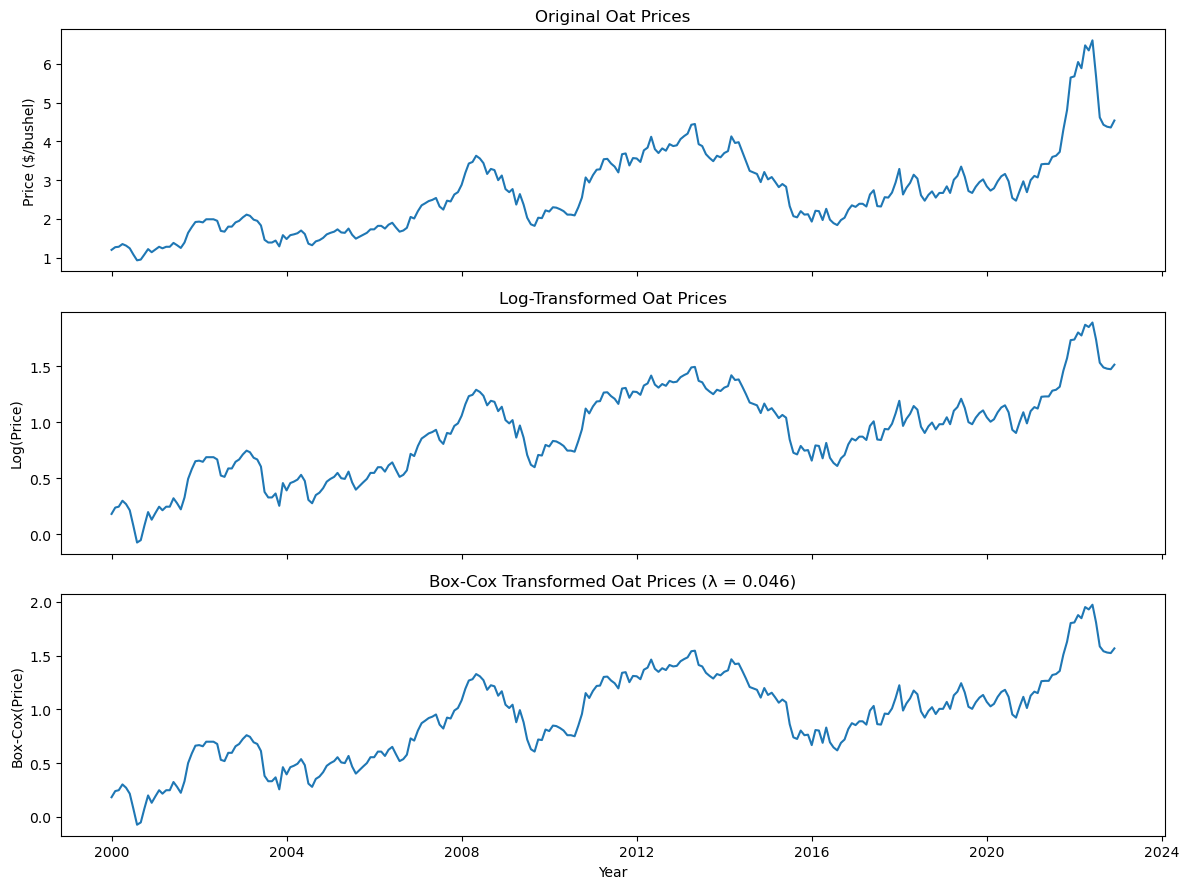

In [25]:

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

axes[0].plot(train_original)
axes[0].set(
    title="Original Oat Prices",
    ylabel="Price ($/bushel)"
)

axes[1].plot(train_log)
axes[1].set(
    title="Log-Transformed Oat Prices",
    ylabel="Log(Price)"
)

axes[2].plot(train_boxcox)
axes[2].set(
    title=f"Box-Cox Transformed Oat Prices (λ = {boxcox_lambda:.3f})",
    xlabel="Year",
    ylabel="Box-Cox(Price)"
)

plt.tight_layout()
plt.show()



### Box-Cox Transformation

The estimated Box-Cox parameter was λ = 0.046, which is very close to zero. This suggests that a natural logarithm transformation may be appropriate for the oat price series.

Both transformations reduce the relative influence of unusually high prices, particularly during 2021–2022. However, further examination is needed to determine whether the transformations stabilize variability or improve forecasting performance.


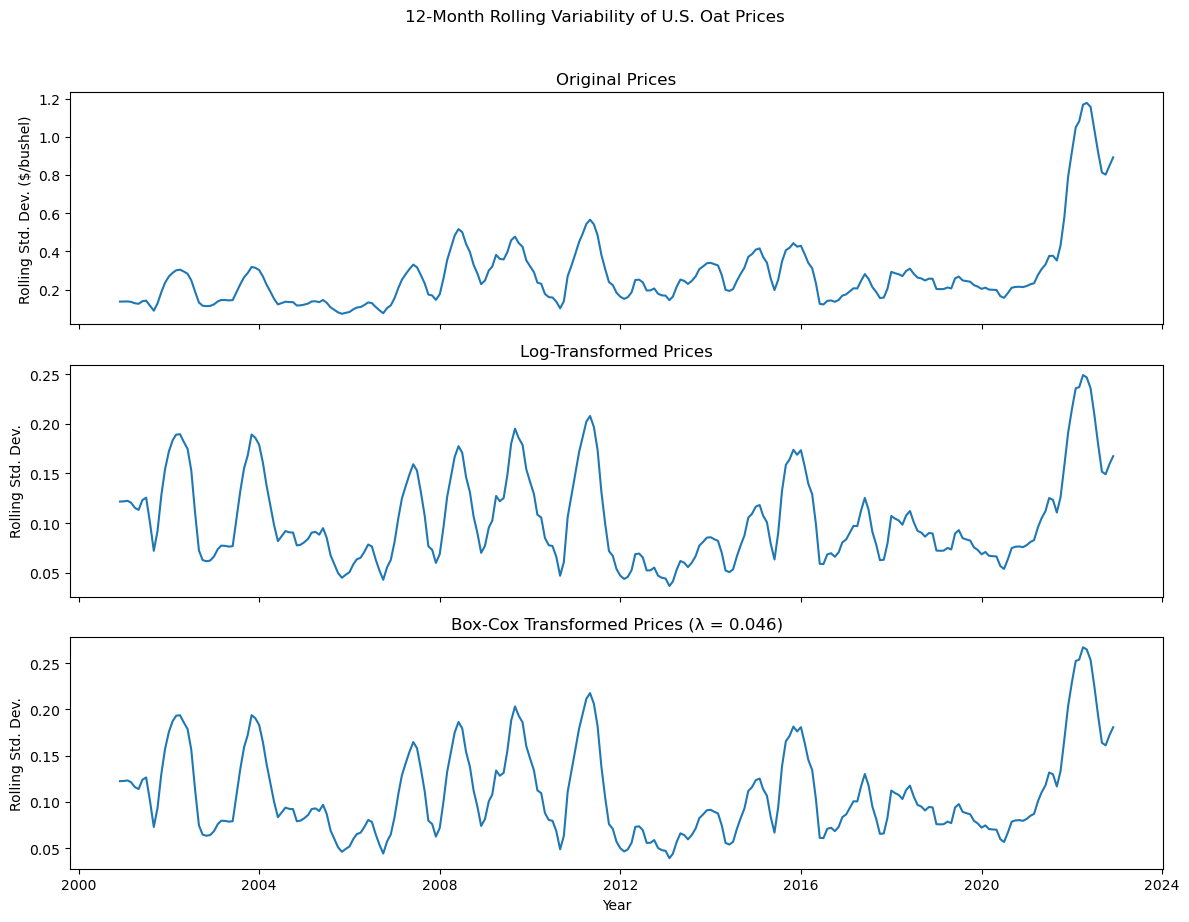

In [26]:

# Calculate 12-month rolling standard deviations
rolling_original = train_original.rolling(12).std()
rolling_log = train_log.rolling(12).std()
rolling_boxcox = train_boxcox.rolling(12).std()

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

axes[0].plot(rolling_original)
axes[0].set(
    title="Original Prices",
    ylabel="Rolling Std. Dev. ($/bushel)"
)

axes[1].plot(rolling_log)
axes[1].set(
    title="Log-Transformed Prices",
    ylabel="Rolling Std. Dev."
)

axes[2].plot(rolling_boxcox)
axes[2].set(
    title=f"Box-Cox Transformed Prices (λ = {boxcox_lambda:.3f})",
    xlabel="Year",
    ylabel="Rolling Std. Dev."
)

plt.suptitle(
    "12-Month Rolling Variability of U.S. Oat Prices",
    y=1.02
)
plt.tight_layout()
plt.show()



### Transformation Results

The estimated Box-Cox parameter was 0.046, suggesting that a log transformation may be appropriate for the oat price series. Both the log and Box-Cox transformations reduced the relative magnitude of price fluctuations around 2021–2022.

However, the rolling standard deviations continued to fluctuate over time, indicating that neither transformation completely stabilized variability. Because the two transformations produced nearly identical results, the simpler log transformation may be preferable if a transformation is used for forecasting.


## 8. Preprocessing Summary

The exploratory analysis identified substantial long-term price fluctuations, relatively weak seasonality, and evidence of nonstationarity in monthly U.S. oat prices.

The dataset required minimal cleaning, as no missing price observations or duplicate records were identified. First differencing was effective in addressing nonstationarity, as supported by the ADF and KPSS tests.

A 12-month moving average helped visualize longer-term trends but introduced lag, so smoothing will not be applied to the forecasting data.

Log and Box-Cox transformations reduced the relative influence of unusually high prices, although neither completely stabilized variability. The estimated Box-Cox parameter was close to zero, suggesting that a log transformation is a reasonable alternative to evaluate.

For subsequent forecasting, the original and log-transformed series can be compared using models with one order of nonseasonal differencing. Seasonal terms may also be considered, although the exploratory analysis suggests relatively weak seasonality.
